# HERIDAL dataset demo

HERIDAL contains high resolution (4000x3000) aerial photos of wilderness terrain with person annotations in Pascal VOC XML format, plus 81x81 patches for classification.

Download it from http://ipsar.fesb.unist.hr/ipsar_data/heridal.zip and extract to `../data/heridal`.

In [1]:
import os
import sys
import xml.etree.ElementTree as ET

import pandas as pd
from PIL import Image, ImageDraw

DATA = '../data/heridal'

## Patch examples

A negative (background) and a positive (person) patch.

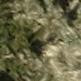

In [2]:
Image.open(os.path.join(DATA, 'patches/negative/neg10011.jpg'))

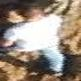

In [3]:
Image.open(os.path.join(DATA, 'patches/positive/pos10000.jpg'))

## A test image with its bounding boxes

In [4]:
tree = ET.parse(os.path.join(DATA, 'testImages/labels/test_BLI_0001.xml'))

sample_annotations = []
for bndbox in tree.getroot().iter('bndbox'):
    sample_annotations.append([
        int(bndbox.find('xmin').text),
        int(bndbox.find('ymin').text),
        int(bndbox.find('xmax').text),
        int(bndbox.find('ymax').text),
    ])
sample_annotations

[[2645, 521, 2751, 596],
 [1976, 525, 2058, 569],
 [1681, 765, 1726, 808],
 [3293, 1445, 3362, 1497],
 [1090, 1314, 1157, 1354]]

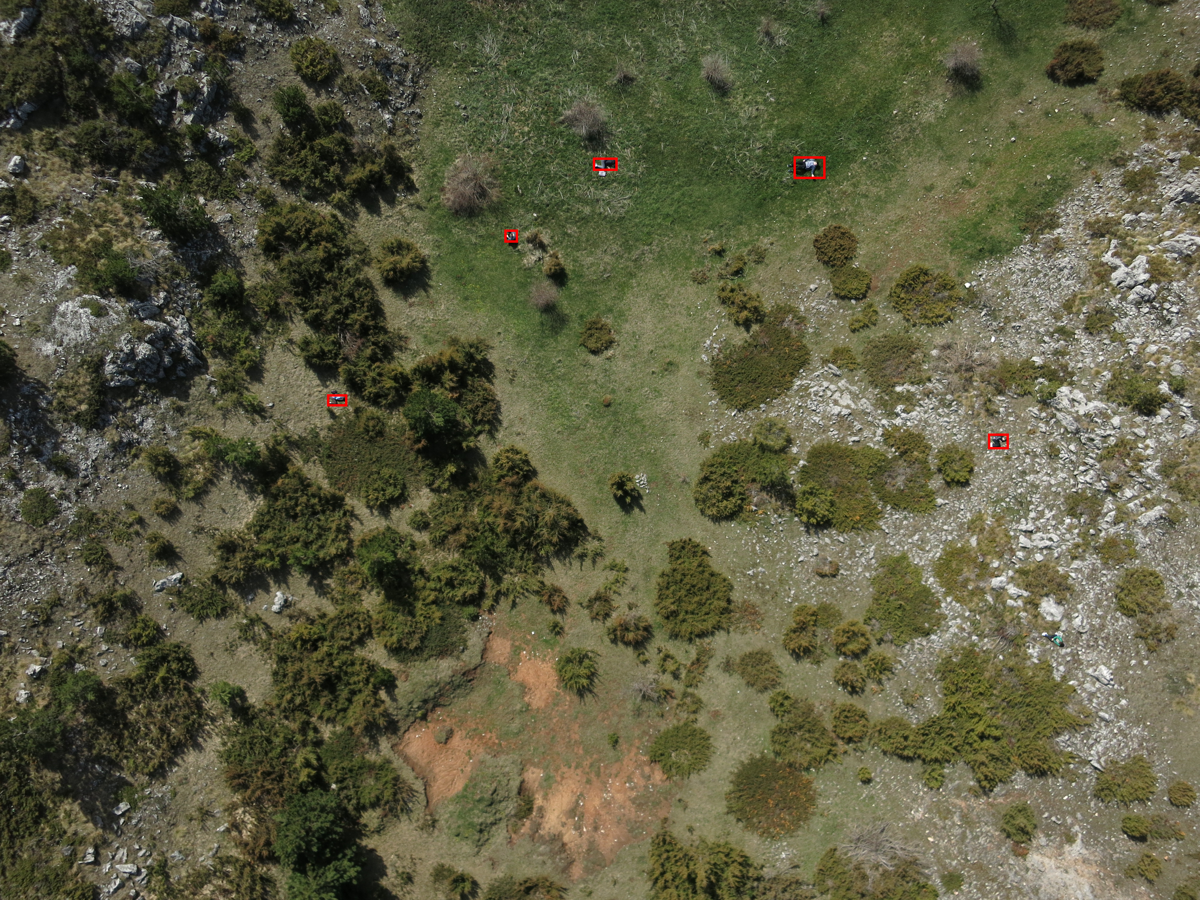

In [5]:
test_image = Image.open(os.path.join(DATA, 'testImages/test_BLI_0001.JPG'))

annotated = test_image.copy()
draw = ImageDraw.Draw(annotated)
for bbox in sample_annotations:
    draw.rectangle(bbox, outline='red', width=8)

# downscale for display, the originals are 12MP
annotated.thumbnail((1200, 1200))
annotated

## Class distribution

In [6]:
def count_files(path):
    return len([n for n in os.listdir(path) if os.path.isfile(os.path.join(path, n))])

counts = {
    'negative patches': count_files(os.path.join(DATA, 'patches/negative')),
    'positive patches': count_files(os.path.join(DATA, 'patches/positive')),
    'train images': count_files(os.path.join(DATA, 'trainImages')),
    'test images': count_files(os.path.join(DATA, 'testImages')),
}
pd.DataFrame({'count': counts})

,count
negative patches,39700
positive patches,29050
train images,1583
test images,101


## Check image dimensions for consistency

In [7]:
def check_img_dims(path, expected_dims):
    issue_found = False
    for name in os.listdir(path):
        full_name = os.path.join(path, name)
        if os.path.isfile(full_name):
            with Image.open(full_name) as img:
                if img.size != expected_dims:
                    issue_found = True
                    print(f'expected {expected_dims} but got {img.size} for {full_name}')
    if not issue_found:
        print(f'all images in {path} are {expected_dims}')

In [8]:
check_img_dims(os.path.join(DATA, 'trainImages'), (4000, 3000))
check_img_dims(os.path.join(DATA, 'testImages'), (4000, 3000))

all images in ../data/heridal\trainImages are (4000, 3000)
expected (4000, 3000) but got (4000, 2250) for ../data/heridal\testImages\test_MED_0001.JPG
expected (4000, 3000) but got (4000, 2250) for ../data/heridal\testImages\test_MED_0002.JPG
expected (4000, 3000) but got (4000, 2250) for ../data/heridal\testImages\test_MED_0004.JPG
expected (4000, 3000) but got (4000, 2250) for ../data/heridal\testImages\test_MED_0006.JPG


## Loading with IPSARDataset

The same directory layout (images with a `labels` subfolder) is what `IPSARDataset` expects, so the raw HERIDAL splits can be loaded directly.

In [9]:
sys.path.append('..')
from drone_sar.ipsar_dataset import IPSARDataset

train_data = IPSARDataset(os.path.join(DATA, 'trainImages'))
item = train_data[0]
print(len(train_data), 'images, first item:', item['target_sizes'], '-', len(item['boxes']), 'boxes')

1583 images, first item: (4000, 3000) - 3 boxes


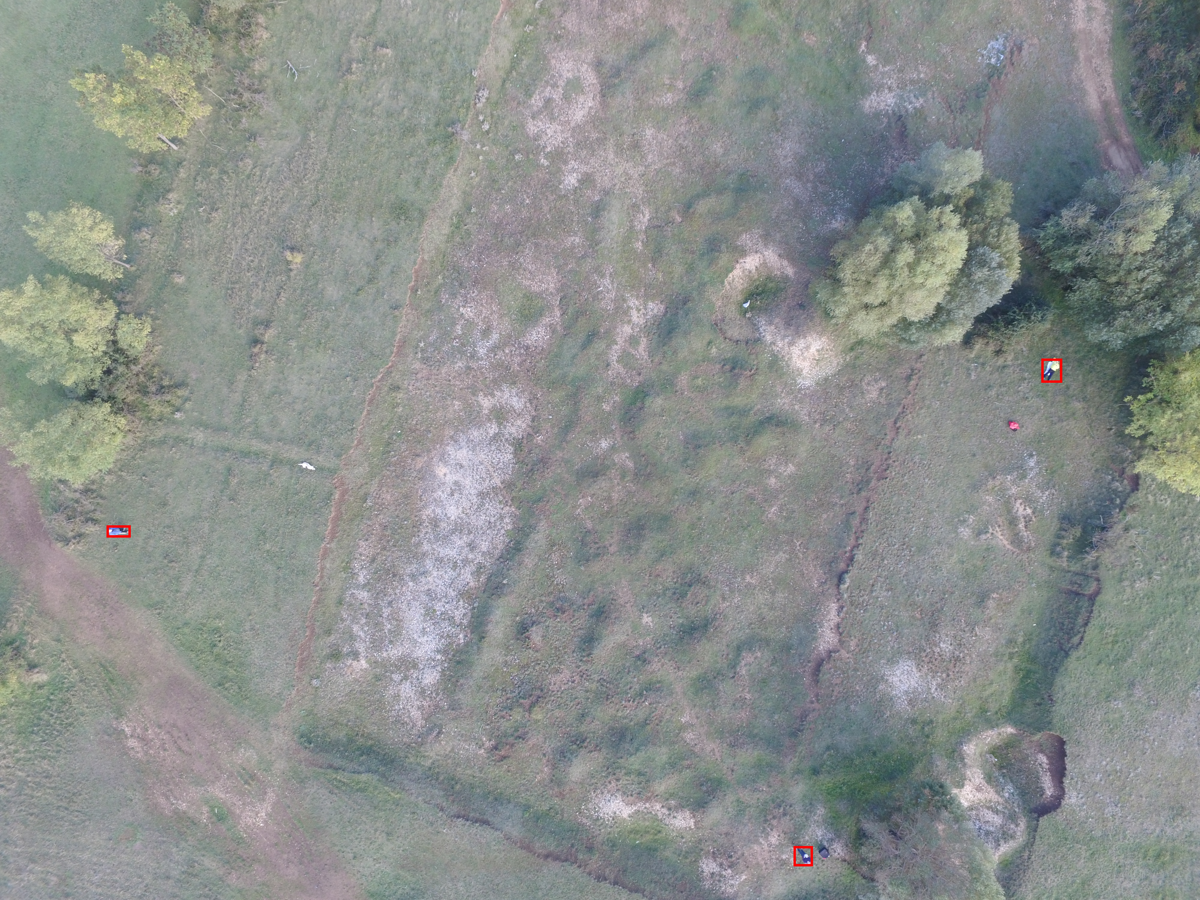

In [10]:
annotated = item['pil'].copy()
draw = ImageDraw.Draw(annotated)
for x, y, w, h in item['boxes'].tolist():
    draw.rectangle([x, y, x + w, y + h], outline='red', width=8)
annotated.thumbnail((1200, 1200))
annotated